# Exercise 03 — R-Wave Detection

**Biomedical Signal and Image Analysis** 

Deadline for the submission: 24.11.2026 at 23.59. Upload a single ZIP file to Stud.IP. Make sure that it is clear, which file presents the solution for which excercise.


### Learning goals

1. Estimate heart rate from an ECG strip.
2. Load and visualize sampled ECG data.
3. Remove an ECG signal trend using a sixth-degree polynomial.
4. Detect R-wave peaks with an amplitude threshold and minimum peak distance.
5. Design and compare low-pass, high-pass, and band-pass Butterworth filters.

**Instructions:** Complete the `TODO` comments in code cells and replace the answer placeholders in Markdown cells. Run the notebook from top to bottom. Keep all relevant plots and short explanations in the submitted notebook.

## Preparation — packages and data file

Place **`ecg.mat` in the same folder as this notebook**.

Required packages: `numpy`, `scipy`, `matplotlib`, and `jupyter`/`notebook` (or JupyterLab). If needed, install them in your Python environment:

```bash
python -m pip install numpy scipy matplotlib jupyter
```

Run the next cell before starting the tasks. It will tell you if the data file is missing or if the expected variable is not present.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import butter, find_peaks, sosfilt

FS = 500  # sampling frequency in Hz (specified in the handout)
DATA_PATH = Path("ecg.mat")

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Cannot find {DATA_PATH.resolve()}. Place ecg.mat next to this notebook."
    )

mat_data = loadmat(DATA_PATH)
if "ecg" not in mat_data:
    available = [k for k in mat_data if not k.startswith("__")]
    raise KeyError(f"Expected the variable 'ecg' in ecg.mat; found: {available}")

ecg = np.asarray(mat_data["ecg"], dtype=float).squeeze()
if ecg.ndim != 1:
    raise ValueError(f"Expected one ECG signal; found array shape {ecg.shape}")
if not np.all(np.isfinite(ecg)):
    raise ValueError("ecg contains NaN or infinite values. Inspect the input data.")

print(f"Loaded ecg.mat: {ecg.size} samples at {FS} Hz")
print(f"Duration: {ecg.size / FS:.3f} seconds")

Loaded ecg.mat: 2000 samples at 500 Hz
Duration: 4.000 seconds


## 1.1 — Determination of heart rate from ECG (2 points)

The approximate heart rate can be determined by counting R-peaks on printed ECG paper.

**Task (2 pts):** Determine the approximate heart rate for the ECG strip shown below. The paper speed is **25 mm/s**. Show your method briefly.

| ECG-paper property | 50 mm/s | 25 mm/s |
|:--|--:|--:|
| Large boxes in 60 s | 600 | 300 |
| Large boxes in 6 s | 60 | 30 |
| Duration of one large box | 0.1 s | 0.2 s |
| Duration of one small box | 0.02 s | 0.04 s |
| Amplitude of one vertical small box | 0.1 mV | 0.1 mV |

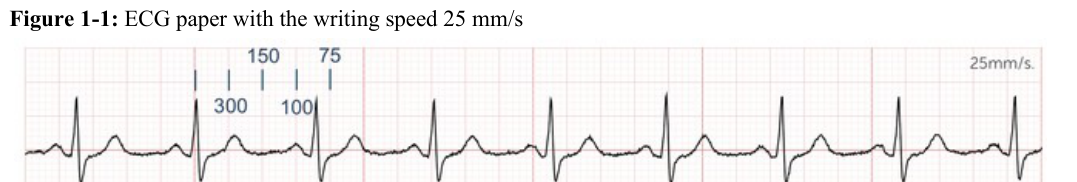

*Figure 1-1 ECG paper, recording speed 25 mm/s.*

*Your answer:**

- Number of large boxes between successive R-peaks (approx.): 3
- R–R interval (seconds): 0.6 s
- Estimated heart rate (beats/min): 100 bpm
- Calculation / explanation: <br>
Distance between successive R-peaks is approximately 3 large boxes, therefore R-R interval: 3 * 0.2 s = 0.6 s <br>
Estimated heart rate = 60/0.6s = 100 bpm

*Hint:* Relate the duration of the R–R interval to 60 seconds; use several consecutive intervals if you want a more robust estimate.

## 1.2 — Visualization of ECG data using Python (3 points)


**Task (3 pts):**

- Create a vector `samples` containing the sample positions.
- Plot `ecg` against `samples` using **Matplotlib**.
- Include a meaningful title, **x-axis in samples**, **y-axis in mV**, and a grid.

You may additionally make a time-axis plot in seconds using `FS = 500`.

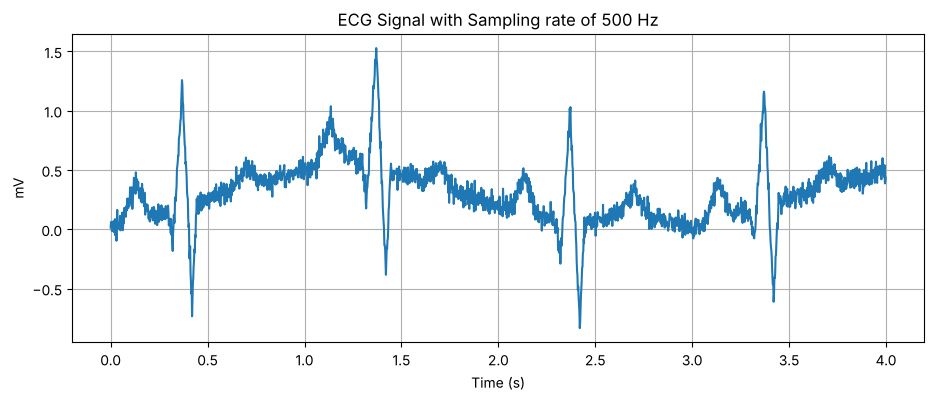

In [2]:
# 1.2 — Complete the visualization
samples = np.arange(len(ecg))  #np.arange(...) with one position per ECG sample
time = samples / FS

if samples is not None:
    fig, ax = plt.subplots(figsize=(11, 4))
    # ax.plot(samples, ecg)
    ax.plot(time,ecg)
    # set title, x-label, y-label, and show the grid
    ax.set_title("ECG Signal with Sampling rate of 500 Hz")
    ax.set_ylabel("mV")
    ax.set_xlabel("Time (s)")
    ax.grid()
    plt.show()
else:
    print("TODO 1.2: create 'samples', then plot and label the ECG.")

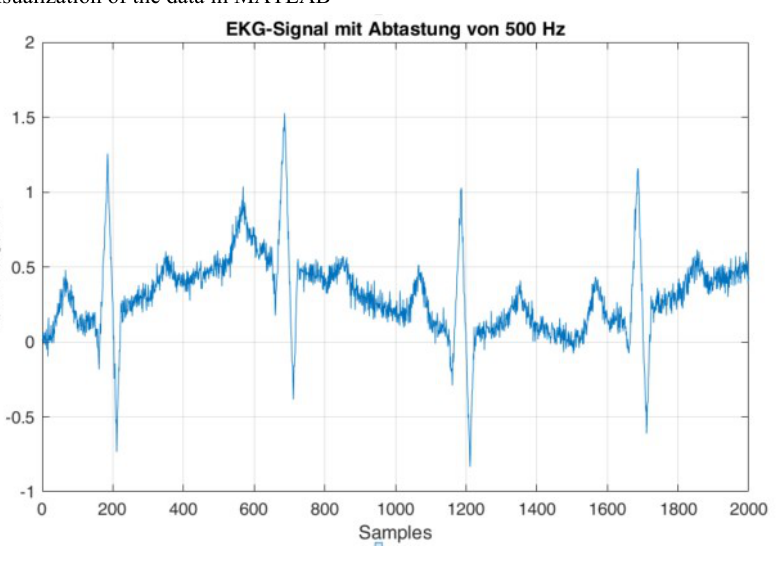

*Reference (Figure 1-2): ECG visualization.*

## 1.3 — ECG trend removal (8 points)

**a) Code (5 pts):** Remove the slowly varying signal trend from `ecg` using a **sixth-degree polynomial**. Subtract the fitted trend to obtain the detrended signal, called `ECG_data` below. Plot the detrended ECG with appropriate axes, title, and grid.

**b) Explanation (3 pts):** Why is it sensible to remove a trend from an ECG before detecting R-waves?


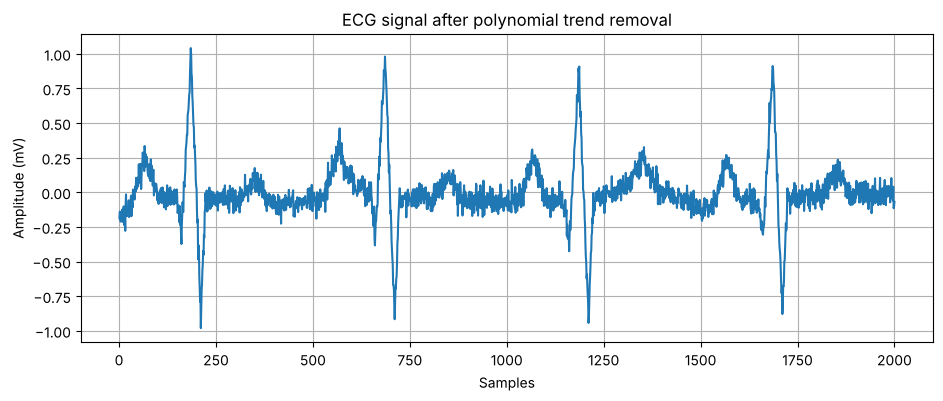

In [3]:
# 1.3a — Sixth-degree polynomial trend removal
x = np.arange(1, ecg.size + 1)

poly_coefficients = np.polyfit(x, ecg, 6)       # fit a polynomial of degree 6 to (x, ecg)
trend = np.polyval(poly_coefficients, x)        # evaluate the fitted polynomial at x
ECG_data = ecg - trend                          # subtract the trend from the original ecg

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(x, ECG_data)
ax.set_title("ECG signal after polynomial trend removal")
ax.set_xlabel("Samples")
ax.set_ylabel("Amplitude (mV)")
ax.grid(True)
plt.show()

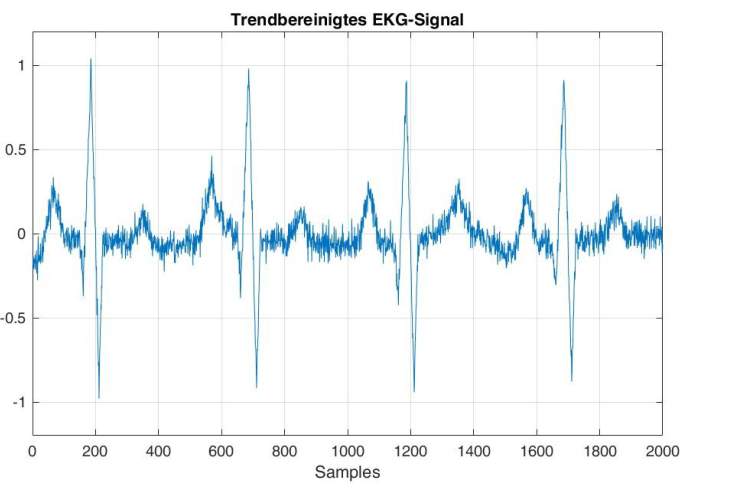

*Reference (Figure 1-3): ECG signal after polynomial trend removal.*

**1.3b — Your explanation (3 pts):**

The recorded ECG contains a slowly varying baseline drift (e.g. from breathing, body movement or electrode/skin effects). The drift shifts the whole signal up and down, so the R-peaks do not sit at a constant level any more. An amplitude-based peak detector with a fixed threshold would then be unreliable: in a part where the baseline is high, P- and T-waves could exceed the threshold (false detections), and in a part where the baseline is low, real R-waves could fall below it (missed detections). After subtracting the sixth-degree polynomial the baseline is roughly centred around 0 mV, so one fixed threshold works for the whole recording.

## 1.4 — Detection of R-waves in ECG data (5 points)

Detect R-wave peaks based on **both their amplitude and their separation**.

**Task (5 pts):** Use `scipy.signal.find_peaks` on your detrended `ECG_data`.

- Set a sensible **minimum peak height** (in signal units).
- Set a sensible **minimum distance between detected peaks** (in samples). Convert a desired time separation to samples using the sampling frequency, if helpful.
- Plot the detrended ECG with detected R-peaks marked by **red downward triangles** and add a legend, title, grid, and axis labels.
- Check visually whether each clear R-wave has exactly one marker; adjust your values if needed.


Detected 4 peaks.


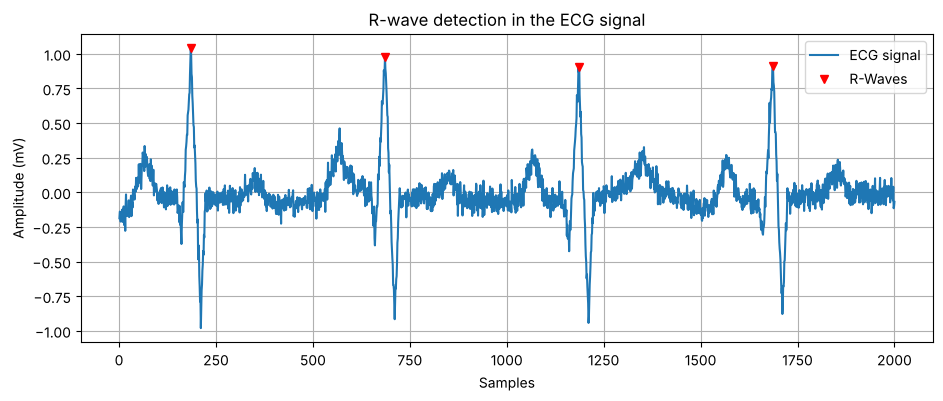

In [4]:
# 1.4 — R-peak detection
min_distance_samples = 400  # integer number of samples
min_peak_height = 0.5      # amplitude threshold based on your detrended ECG
locs_Rwave = None

if ECG_data is None:
    print("Complete trend removal (1.3) first.")
elif min_distance_samples is None or min_peak_height is None:
    print("TODO 1.4: choose minimum peak distance and minimum peak height.")
else:
    locs_Rwave, peak_properties = find_peaks(
        ECG_data,
        distance=min_distance_samples,
        height=min_peak_height,
    )

    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(np.arange(1, ecg.size + 1), ECG_data, label="ECG signal")
    ax.plot(
        locs_Rwave + 1,
        ECG_data[locs_Rwave],
        "rv",
        markerfacecolor="red",
        label="R-Waves",
    )
    ax.set_xlabel("Samples")
    ax.set_ylabel("Amplitude (mV)")
    ax.set_title("R-wave detection in the ECG signal")
    ax.grid(True)
    ax.legend()
    plt.show()
    print(f"Detected {len(locs_Rwave)} peaks.")

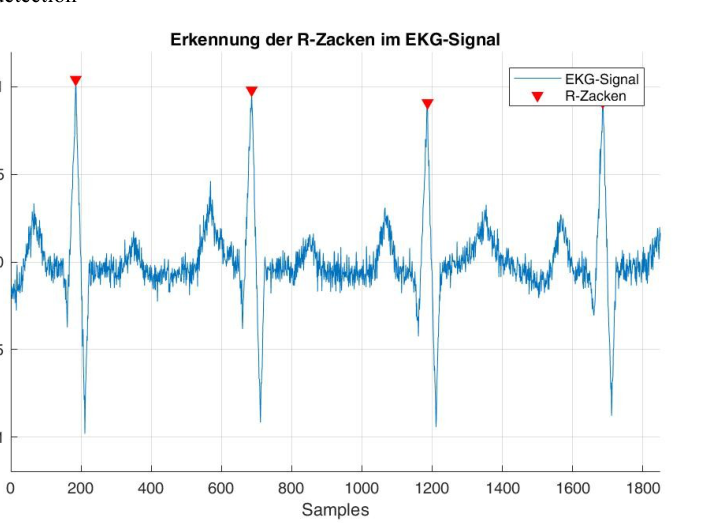

*Reference (Figure 1-4): expected form of the R-wave detection plot; your settings must be justified by your data.*

**Your chosen detection settings:**

- Minimum distance (samples and corresponding seconds): 400
- Minimum peak height (signal amplitude): 0.5
- Brief justification and visual check: <br>
A minimum distance of 400 samples prevents multiple detections within the same heartbeat while allowing the R-peaks visible in this recording to be detected. The amplitude threshold of 0.5 mV excludes smaller peaks, including P- and T-waves, provided they remain below this threshold.

Compute R–R intervals and use their mean to estimate the heart rate.

In [5]:
#estimate the heart rate.

print("Detected Peaks: ", locs_Rwave)
rr_interval = np.diff(locs_Rwave) / FS
print("R-R intervals in s: ", rr_interval)
hr = 60 / np.mean(rr_interval)
print("Heart Rate :", hr)

Detected Peaks:  [ 184  685 1186 1685]
R-R intervals in s:  [1.002 1.002 0.998]
Heart Rate : 59.96002664890074


## 1.5 — High-pass, low-pass, and band-pass filters (12 points)


**a) Low-pass filter (2 pts):** Below you find a Butterworth low-pass filter with **unsuitable settings**: order **1**, cutoff **80 Hz**, sampling frequency **500 Hz**. Adjust those parameters to obtain a useful low-pass-filtered ECG.

**b) Other filters (6 pts):** Following the low-pass example, implement a **high-pass** and a **band-pass** Butterworth filter. Visualize each filtered signal next to the original.

**c) Explanation (4 pts):** Explain why your filter types, cutoff frequencies, and orders are appropriate. Discuss what noise or distortion they target and whether they preserve the QRS/R-wave features.


In [6]:
# Helper — compare an original signal with a filtered signal
sample_positions = np.arange(1, ecg.size + 1)

def plot_filter_comparison(original, filtered, filtered_label):
    fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    axes[0].plot(sample_positions, original)
    axes[0].set_title("Original ECG")
    axes[1].plot(sample_positions, filtered)
    axes[1].set_title(filtered_label)
    for ax in axes:
        ax.set_ylabel("Amplitude (mV)")
        ax.grid(True)
    axes[-1].set_xlabel("Samples")
    fig.tight_layout()
    plt.show()

### 1.5a — Low-pass filter (2 points)

**Starter values below intentionally reproduce the unsuitable source example.** Change the filter order and/or cutoff frequency, rerun the cell, and compare the waveform against the original ECG.

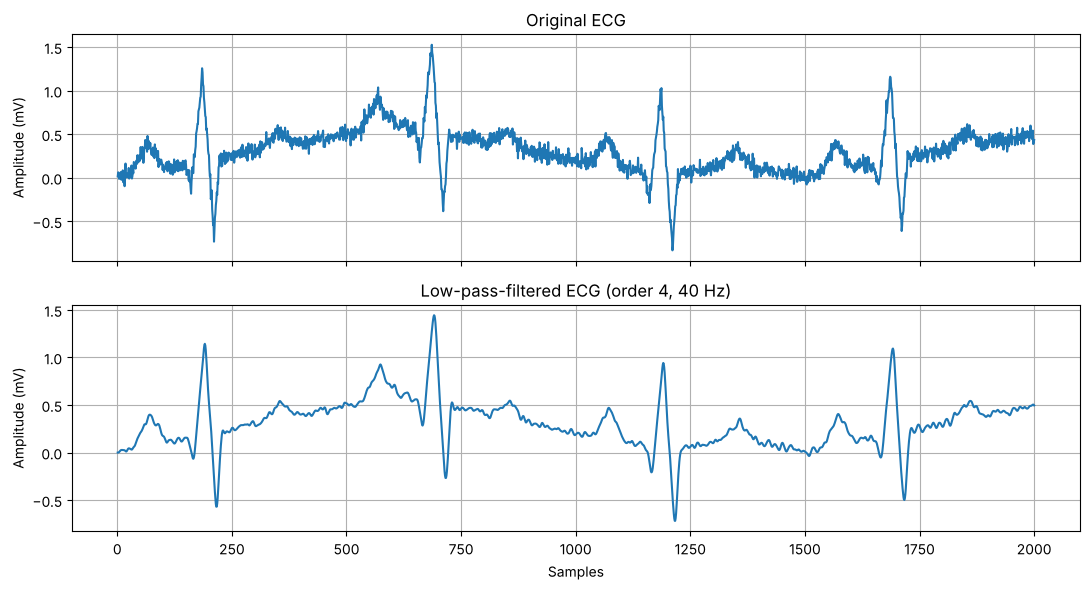

In [7]:
# 1.5a — Low-pass Butterworth filter: improved settings
low_order = 4       # steeper roll-off than order 1 (order 1 hardly attenuates anything above the cutoff)
low_cutoff_hz = 40  # keeps the QRS energy (< ~40 Hz) and removes high-frequency noise above it

low_sos = butter(low_order, low_cutoff_hz, btype="lowpass", fs=FS, output="sos")
low_filtered = sosfilt(low_sos, ecg)
plot_filter_comparison(ecg, low_filtered, "Low-pass-filtered ECG (order 4, 40 Hz)")

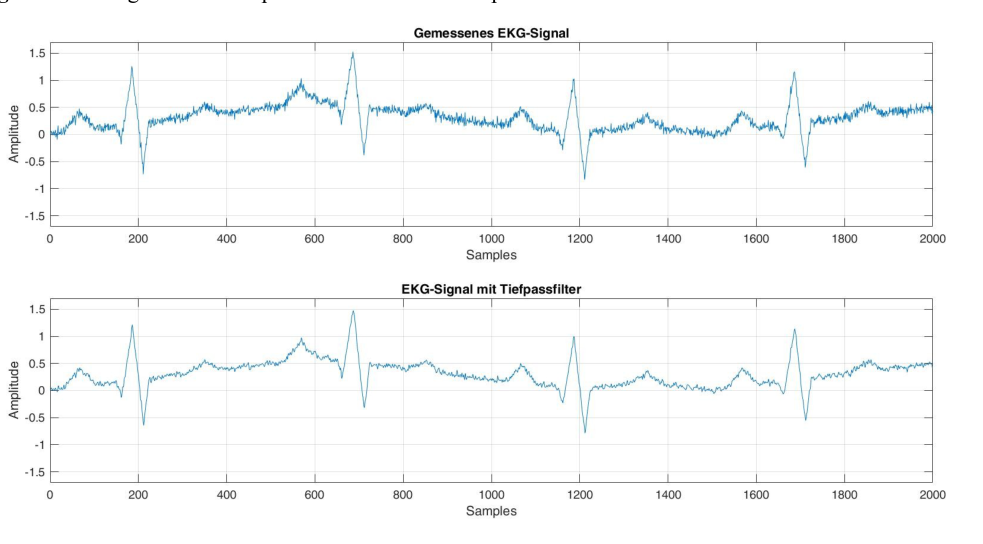

*Reference (Figure 1-5): the *unsuitable initial low-pass-filter settings*.*

### 1.5b — High-pass and band-pass filters (6 points)

Complete both implementations below. Remember that a band-pass filter uses **two** cutoff frequencies. Compare each filter's effect visually instead of assuming that any filter is automatically better.

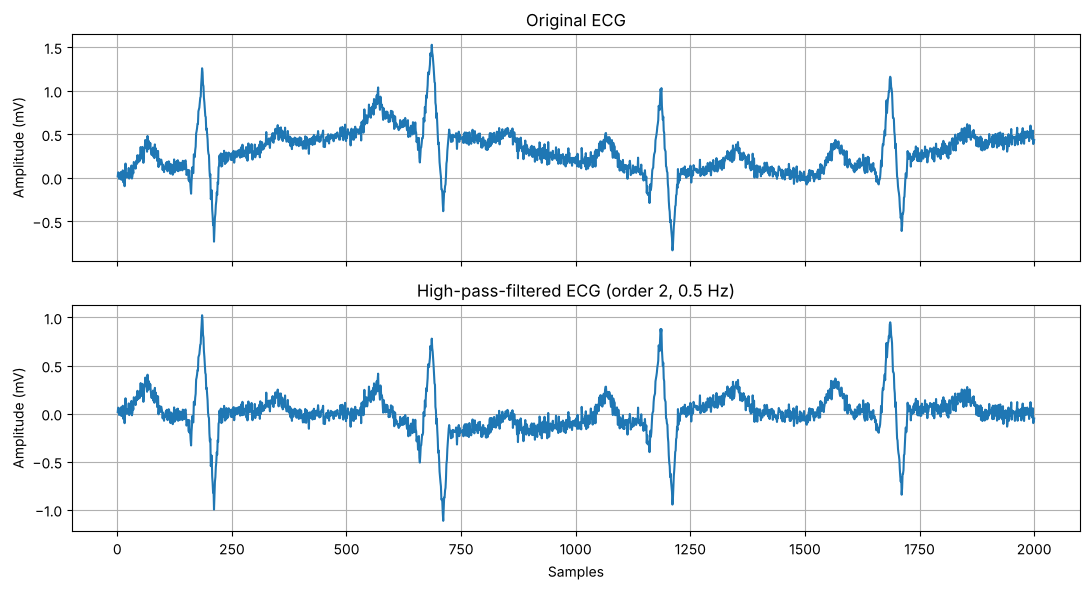

In [8]:
# 1.5b — High-pass Butterworth filter
high_order = 2         # low order: gentle filter, little ringing
high_cutoff_hz = 0.5   # removes baseline drift (< 0.5 Hz) but keeps the ECG waves

if high_order is None or high_cutoff_hz is None:
    print("TODO 1.5b: choose high-pass order and cutoff frequency.")
else:
    high_sos = butter(high_order, high_cutoff_hz, btype="highpass", fs=FS, output="sos")
    high_filtered = sosfilt(high_sos, ecg)
    plot_filter_comparison(ecg, high_filtered, "High-pass-filtered ECG (order 2, 0.5 Hz)")

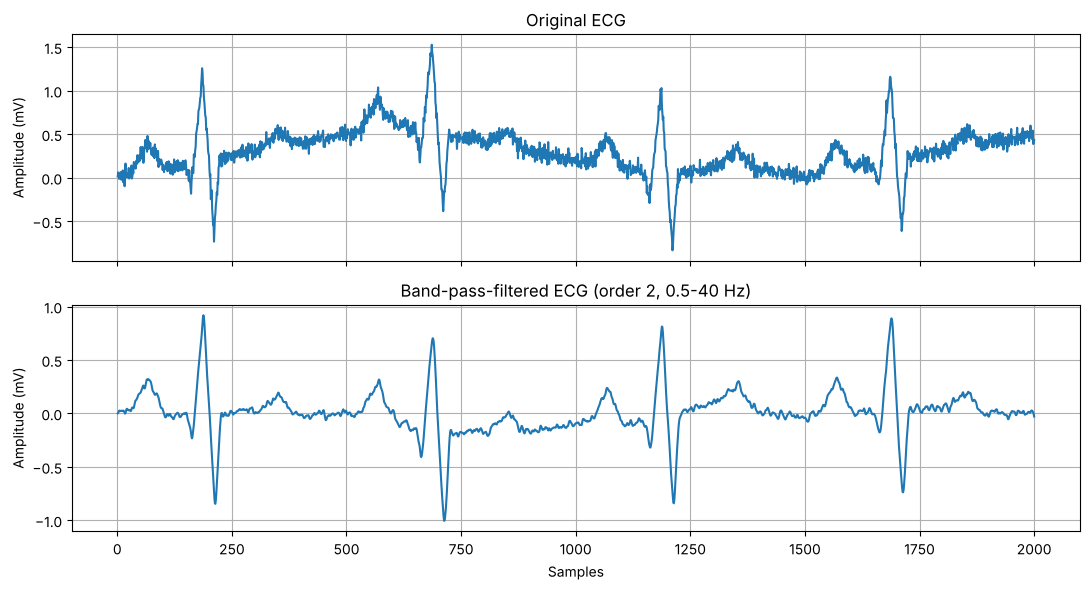

In [9]:
# 1.5b — Band-pass Butterworth filter
band_order = 2        # for a band-pass the effective filter order is 2 * band_order = 4
band_low_hz = 0.5     # lower cutoff: removes baseline drift
band_high_hz = 40     # upper cutoff: removes high-frequency noise

if None in (band_order, band_low_hz, band_high_hz):
    print("TODO 1.5b: choose band-pass order and both cutoff frequencies.")
else:
    band_sos = butter(band_order, [band_low_hz, band_high_hz], btype="bandpass", fs=FS, output="sos")
    band_filtered = sosfilt(band_sos, ecg)
    plot_filter_comparison(ecg, band_filtered, "Band-pass-filtered ECG (order 2, 0.5-40 Hz)")

In [10]:
# Extra — quantify the filter effects (used for the discussion in 1.5c)
def describe(name, signal):
    peaks, _ = find_peaks(signal, distance=min_distance_samples, height=0.3)
    noise = np.std(np.diff(signal))   # sample-to-sample change: a simple measure of high-frequency noise
    print(f"{name:<10} R-peak amplitude: {signal[peaks].mean():5.2f} mV | "
          f"mean R-peak delay vs. original: {np.mean(peaks - locs_Rwave) / FS * 1000:5.1f} ms | "
          f"high-frequency noise: {noise:.4f}")

describe("Original", ecg)
describe("Low-pass", low_filtered)
describe("High-pass", high_filtered)
describe("Band-pass", band_filtered)

Original   R-peak amplitude:  1.24 mV | mean R-peak delay vs. original:   0.0 ms | high-frequency noise: 0.0755
Low-pass   R-peak amplitude:  1.16 mV | mean R-peak delay vs. original:  10.5 ms | high-frequency noise: 0.0229
High-pass  R-peak amplitude:  0.91 mV | mean R-peak delay vs. original:  -1.0 ms | high-frequency noise: 0.0755
Band-pass  R-peak amplitude:  0.83 mV | mean R-peak delay vs. original:   4.5 ms | high-frequency noise: 0.0233


### 1.5c — Justification (4 points)

| Filter | Order | Cutoff frequency/frequencies (Hz) | Intended purpose | Possible side effect |
|:--|:--|:--|:--|:--|
| Low-pass | 4 | 40 | Suppress high-frequency noise (muscle noise, power-line interference at 50 Hz, electronic noise) | Slightly rounds and lowers the sharp R-peak; delays the signal; baseline drift is not removed |
| High-pass | 2 | 0.5 | Remove baseline drift (breathing, movement) | High-frequency noise stays; too high a cutoff would distort the ST segment and T-wave |
| Band-pass | 2 (effective order 4) | 0.5 – 40 | Do both at once: remove drift and high-frequency noise | Combines the side effects of both: small delay (about 4-5 ms) and slightly smoothed QRS |

**Your explanation:**

The ECG contains three different components: the useful signal, a slow baseline drift (below about 0.5 Hz) and high-frequency noise. The QRS complex, which contains the R-wave, has most of its energy between roughly 5 and 40 Hz, and the P- and T-waves lie at even lower frequencies. For this reason a cutoff of 40 Hz for the low-pass is a compromise: it removes noise (including 50 Hz power-line interference) while keeping the shape of the QRS complex. The original example (order 1, 80 Hz) is unsuitable because a first-order filter has a very slow roll-off, so noise above 80 Hz is hardly reduced. Order 4 gives a much steeper roll-off and still has a smooth response. The high-pass at 0.5 Hz is far below the lowest heart-rate frequency (about 1 Hz at 60 bpm), so it removes the drift without changing the waves; a higher cutoff would start to distort the ST segment and the T-wave. The band-pass combines both filters and gives the cleanest result for R-wave detection. The measurements printed in the cell above show the side effects. The low-pass and band-pass filters reduce the high-frequency noise by about 70 % (0.0755 to about 0.023). The low-pass filter slightly rounds the QRS complex (R-peak 1.24 mV to 1.16 mV, and the S-wave is also less deep), and it delays the R-peaks by about 10 ms, because `sosfilt` is a causal (forward-only) filter and therefore adds a phase delay; the band-pass filter delays them by about 4-5 ms. The high-pass filter does not change the noise and leaves the R-peak position almost unchanged (about -1 ms). The lower R-peak amplitudes of the high-pass (0.91 mV) and band-pass (0.83 mV) results are not caused by distortion of the QRS complex; they are measured relative to the corrected baseline, because the offset and drift of about 0.3-0.5 mV are removed. In all three cases the R-peaks are still clearly visible and the beat-to-beat timing (and so the heart rate) is preserved. If a zero-phase result were needed, `sosfiltfilt` could be used instead of `sosfilt`.